# Publication-grade analysis: nonlinear demand–supply–price model

This notebook is a strengthened reproducibility workflow for the manuscript **“Stability Analysis of a Demand–Supply–Price Model and its Empirical Application to the U.S. Crude Oil Market.”**

### Main improvements
1. Separates the **full 8-parameter model** from the empirically preferred **reduced 6-parameter model** with \(a=\zeta=0\).
2. Uses the reduced model for the principal uncertainty analysis, reducing boundary-identification pathologies.
3. Reports Jacobian-based uncertainty **and a moving-block bootstrap with convergence diagnostics**.
4. Retains the 97-month free-running structural extrapolation test, but adds **rolling-origin 1-, 3-, 6-, and 12-month forecasts**.
5. Compares forecasts with a **persistence benchmark** instead of interpreting negative long-horizon \(R^2\) in isolation.
6. Adds **HAC/Newey–West inference** for the empirical price-growth/imbalance diagnostic.
7. Provides annotated global sensitivity heatmaps and reports the valid Monte Carlo sample.
8. Treats numerical continuation as confirmation of the analytical **no-\(\chi\)-Hopf** result, not as a search for a desired bifurcation.
9. Uses \(\Omega=a\eta+\nu(b-\zeta)\) consistently.
10. Exports publication-ready tables, figures, and a machine-readable results summary.

`FAST_MODE=True` is for checking the notebook. Set `FAST_MODE=False` for the final manuscript run.

In [1]:
import os, math, json, warnings, platform, sys
from pathlib import Path
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.integrate import solve_ivp
from scipy.optimize import least_squares
from numpy.linalg import eigvals, pinv
from scipy.stats import spearmanr

try:
    import statsmodels.api as sm
    HAVE_STATSMODELS = True
except Exception:
    HAVE_STATSMODELS = False

SEED = 20261015
rng = np.random.default_rng(SEED)

FAST_MODE = True

# Publication settings
N_STARTS_FULL = 8 if FAST_MODE else 40
N_STARTS_REDUCED = 8 if FAST_MODE else 40
BOOTSTRAP_TARGET = 50 if FAST_MODE else 1000      # successful replications
BOOTSTRAP_MAX_ATTEMPTS = 100 if FAST_MODE else 1600
MC_SENSITIVITY = 400 if FAST_MODE else 5000
ROLLING_REFIT_STARTS = 2 if FAST_MODE else 8

FIGDIR = Path("figures")
TABDIR = Path("tables")
FIGDIR.mkdir(exist_ok=True)
TABDIR.mkdir(exist_ok=True)

plt.rcParams.update({
    "figure.figsize": (9, 5),
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 11
})

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("FAST_MODE =", FAST_MODE)

Python: 3.14.6
NumPy: 2.4.6
Pandas: 3.0.3
FAST_MODE = True


## 1. Load and verify the harmonized EIA data

In [2]:
candidates = [
    Path("EIA_LV_Demand_Supply_Harmonized.xlsx"),
    Path("/mnt/data/EIA_LV_Demand_Supply_Harmonized.xlsx")
]
DATA_FILE = next((p for p in candidates if p.exists()), None)
if DATA_FILE is None:
    raise FileNotFoundError("Place EIA_LV_Demand_Supply_Harmonized.xlsx beside the notebook.")

df = pd.read_excel(DATA_FILE, sheet_name="LV Ready")
df.columns = ["t", "date", "D_raw", "S_raw", "P_raw", "d", "s", "p"]
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").reset_index(drop=True)

assert len(df) == 485
assert df[["d","s","p"]].notna().all().all()
assert (df[["d","s","p"]] > 0).all().all()
assert df["date"].is_monotonic_increasing

Y = df[["d","s","p"]].to_numpy(float)
t = df["t"].to_numpy(float)
x0 = Y[0].copy()
STATE_NAMES = ["Demand", "Supply", "Price"]

print(f"Sample: {df.date.min().date()} to {df.date.max().date()} | N={len(df)}")
display(df.head())

Sample: 1986-01-01 to 2026-05-01 | N=485


,t,date,D_raw,S_raw,P_raw,d,s,p
0,0,1986-01-01,498728,283248,22.925455,0.860666,1.179242,0.473092
1,1,1986-02-01,453209,256855,15.454737,0.782113,1.069361,0.318926
2,2,1986-03-01,504565,279413,12.612500,0.870739,1.163276,0.260273
3,3,1986-04-01,478339,265917,12.843636,0.825481,1.107088,0.265043
4,4,1986-05-01,495789,273964,15.377619,0.855594,1.140590,0.317334


,count,mean,std,min,25%,50%,75%,max
D_raw,485.0,579467.288660,45860.339785,436455.000000,542427.000000,585109.000000,616161.000000,671648.000000
S_raw,485.0,240194.917526,79267.920472,119208.000000,176441.000000,214269.000000,282371.000000,429777.000000
P_raw,485.0,48.458743,29.466584,11.347273,20.252500,43.149524,71.533158,133.880000
d,485.0,1.000000,0.079142,0.753200,0.936079,1.009736,1.063323,1.159078
s,485.0,1.000000,0.330015,0.496297,0.734574,0.892063,1.175591,1.789284
p,485.0,1.000000,0.608076,0.234164,0.417933,0.890438,1.476166,2.762763


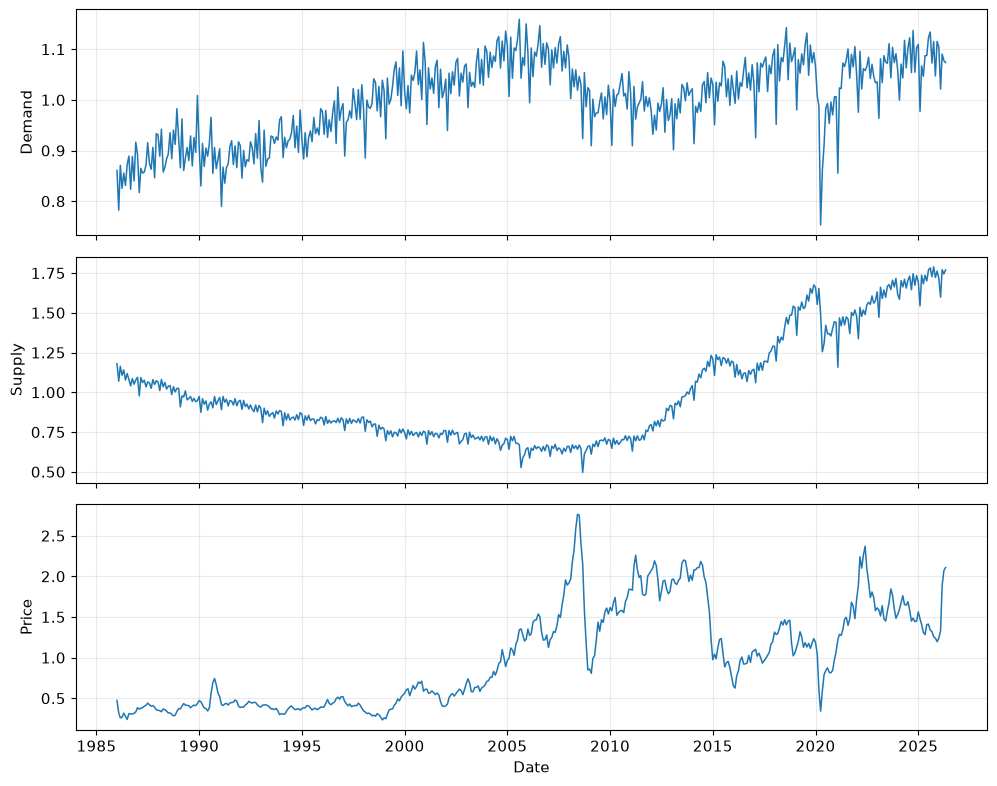

In [3]:
desc = df[["D_raw","S_raw","P_raw","d","s","p"]].describe().T
display(desc)
desc.to_csv(TABDIR/"descriptive_statistics.csv")

fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
for j, col in enumerate(["d","s","p"]):
    axes[j].plot(df["date"], df[col], lw=1.1)
    axes[j].set_ylabel(STATE_NAMES[j])
axes[-1].set_xlabel("Date")
fig.tight_layout()
fig.savefig(FIGDIR/"normalized_states.png", dpi=300, bbox_inches="tight")
plt.show()

## 2. Model, solver, metrics, and estimation utilities

In [4]:
FULL_NAMES = ["rho","a","nu","mu","b","zeta","eta","chi"]
REDUCED_NAMES = ["rho","nu","mu","b","eta","chi"]

def rhs_autonomous(t, x, theta):
    rho,a,nu,mu,b,zeta,eta,chi = np.asarray(theta, float)
    d,s,p = np.maximum(np.asarray(x,float), 1e-12)
    return np.array([
        d*(rho-a*d-nu*p),
        s*(-mu-b*s+zeta*d+eta*p),
        chi*p*(d-s)/max(d+s,1e-12)
    ])

def simulate(theta, t_eval, x_init):
    t_eval = np.asarray(t_eval,float)
    sol = solve_ivp(
        rhs_autonomous, (float(t_eval[0]),float(t_eval[-1])),
        np.asarray(x_init,float), t_eval=t_eval, args=(np.asarray(theta,float),),
        method="LSODA", rtol=1e-8, atol=1e-10
    )
    if (not sol.success) or sol.y.shape[1] != len(t_eval):
        return None
    out = sol.y.T
    if not np.isfinite(out).all():
        return None
    return out

def metrics(y, yh):
    e = np.asarray(y)-np.asarray(yh)
    den = np.sum((y-np.mean(y))**2)
    return {
        "SSE": float(np.sum(e**2)),
        "RMSE": float(np.sqrt(np.mean(e**2))),
        "MAE": float(np.mean(np.abs(e))),
        "R2": float(1-np.sum(e**2)/den) if den > 0 else np.nan
    }

def state_metrics(Yobs, Yhat):
    return pd.DataFrame(
        [metrics(Yobs[:,j],Yhat[:,j]) for j in range(3)],
        index=STATE_NAMES
    )

def reduced_to_full(theta6):
    rho,nu,mu,b,eta,chi = np.asarray(theta6,float)
    return np.array([rho,0.0,nu,mu,b,0.0,eta,chi])

def full_to_reduced(theta8):
    rho,a,nu,mu,b,zeta,eta,chi = theta8
    return np.array([rho,nu,mu,b,eta,chi])

def residual_log(logtheta, t_eval, Yobs, x_init, reduced=False):
    vals = np.exp(np.clip(logtheta,-35,5))
    theta = reduced_to_full(vals) if reduced else vals
    pred = simulate(theta,t_eval,x_init)
    if pred is None:
        return np.full(Yobs.size,1e6)
    return (pred-Yobs).ravel()

def multistart_fit(start_theta, t_eval, Yobs, x_init, reduced=False,
                   n_starts=10, max_nfev=3000, seed=SEED):
    rrng = np.random.default_rng(seed)
    starts = [np.log(np.asarray(start_theta,float))]
    for _ in range(n_starts-1):
        starts.append(starts[0] + rrng.normal(0,0.75,len(start_theta)))
    fits=[]
    for i,z0 in enumerate(starts,1):
        r = least_squares(
            residual_log,z0,args=(t_eval,Yobs,x_init,reduced),
            method="trf",max_nfev=max_nfev,
            xtol=1e-9,ftol=1e-9,gtol=1e-9
        )
        fits.append(r)
        print(f"{i:02d}/{n_starts}: SSE={2*r.cost:.6f} success={r.success}")
    best=min(fits,key=lambda r:r.cost)
    vals=np.exp(best.x)
    theta= reduced_to_full(vals) if reduced else vals
    pred=simulate(theta,t_eval,x_init)
    return theta,best,pred

def information_criteria(sse,n_scalar,k):
    return (
        n_scalar*np.log(sse/n_scalar)+2*k,
        n_scalar*np.log(sse/n_scalar)+k*np.log(n_scalar)
    )

## 3. Full model and principled model reduction

In [5]:
theta_reference = np.array([
    9.3347e-4,3.2e-9,2.8227e-4,3.7058e-3,
    4.7132e-3,3.607e-9,8.5061e-3,3.3518e-2
])

theta_full, fit_full, Yhat_full = multistart_fit(
    theta_reference,t,Y,x0,reduced=False,n_starts=N_STARTS_FULL,
    max_nfev=1500 if FAST_MODE else 5000
)

full_table=pd.DataFrame({"Parameter":FULL_NAMES,"Estimate":theta_full})
display(full_table)
display(state_metrics(Y,Yhat_full))

01/8: SSE=72.145897 success=True
02/8: SSE=72.145897 success=True
03/8: SSE=367.562029 success=True
04/8: SSE=72.145897 success=True
05/8: SSE=72.145897 success=True
06/8: SSE=72.145898 success=True
07/8: SSE=72.145898 success=True
08/8: SSE=72.145897 success=True


,Parameter,Estimate
0,rho,9.337548e-04
1,a,5.967884e-22
2,nu,2.826796e-04
3,mu,3.708140e-03
4,b,4.709213e-03
5,zeta,2.775928e-14
6,eta,8.505079e-03
7,chi,3.351467e-02


,SSE,RMSE,MAE,R2
Demand,2.576875,0.072891,0.057379,0.149976
Supply,7.117260,0.121139,0.099828,0.864979
Price,62.451763,0.358841,0.261076,0.651033


In [6]:
# Reduced model a=zeta=0, motivated by the boundary estimates in the full model.
start6 = full_to_reduced(theta_full)
theta_reduced, fit_reduced, Yhat_reduced = multistart_fit(
    start6,t,Y,x0,reduced=True,n_starts=N_STARTS_REDUCED,
    max_nfev=1500 if FAST_MODE else 5000,seed=SEED+1
)

SSE_full=float(np.sum((Y-Yhat_full)**2))
SSE_red=float(np.sum((Y-Yhat_reduced)**2))
AIC_full,BIC_full=information_criteria(SSE_full,Y.size,8)
AIC_red,BIC_red=information_criteria(SSE_red,Y.size,6)

model_selection=pd.DataFrame([
    ["Full",8,SSE_full,AIC_full,BIC_full],
    [r"Reduced ($a=\zeta=0$)",6,SSE_red,AIC_red,BIC_red]
],columns=["Model","k","SSE","AIC","BIC"])
display(model_selection)

pd.DataFrame({"Parameter":FULL_NAMES,"Estimate":theta_reduced}).to_csv(
    TABDIR/"reduced_parameter_estimates_full_vector.csv",index=False)
model_selection.to_csv(TABDIR/"model_selection.csv",index=False)

01/8: SSE=72.145897 success=True
02/8: SSE=72.145899 success=True
03/8: SSE=72.145898 success=True
04/8: SSE=72.145897 success=True
05/8: SSE=72.145898 success=True
06/8: SSE=72.145898 success=True
07/8: SSE=73.390261 success=True
08/8: SSE=72.145898 success=True


,Model,k,SSE,AIC,BIC
0,Full,8,72.145897,-4354.922952,-4312.660862
1,Reduced ($a=\zeta=0$),6,72.145897,-4358.922952,-4327.226384


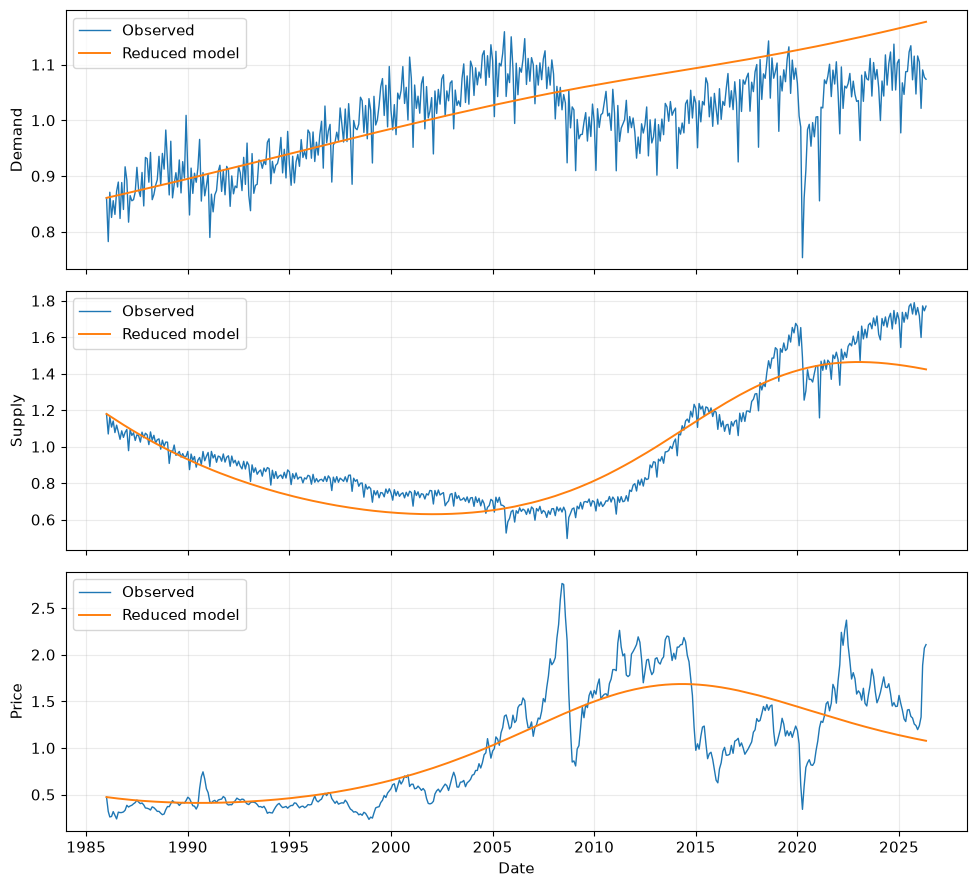

In [7]:
fig, axes = plt.subplots(3,1,figsize=(10,9),sharex=True)
for j,ax in enumerate(axes):
    ax.plot(df.date,Y[:,j],lw=1.0,label="Observed")
    ax.plot(df.date,Yhat_reduced[:,j],lw=1.4,label="Reduced model")
    ax.set_ylabel(STATE_NAMES[j])
    ax.legend()
axes[-1].set_xlabel("Date")
fig.tight_layout()
fig.savefig(FIGDIR/"reduced_observed_fitted_panel.png",dpi=300,bbox_inches="tight")
plt.show()

## 4. Parameter uncertainty for the reduced model

The main inferential table is based on the empirically preferred six-parameter model. This avoids presenting unstable confidence intervals for parameters that collapse to the numerical boundary in the full model.

The moving-block bootstrap targets a specified number of **successful** replications and reports the convergence rate. For publication, run with `FAST_MODE=False`.

In [8]:
# Local covariance in log-parameter space for reduced model
nres=fit_reduced.fun.size
kpar=len(fit_reduced.x)
sigma2=np.sum(fit_reduced.fun**2)/(nres-kpar)
cov_log=sigma2*pinv(fit_reduced.jac.T@fit_reduced.jac)
se_log=np.sqrt(np.maximum(np.diag(cov_log),0))
est6=np.exp(fit_reduced.x)
se6=est6*se_log
z=1.959963984540054
lo6=np.exp(fit_reduced.x-z*se_log)
hi6=np.exp(fit_reduced.x+z*se_log)

local_unc=pd.DataFrame({
    "Parameter":REDUCED_NAMES,"Estimate":est6,
    "SE_delta":se6,"CI95_low":lo6,"CI95_high":hi6
})
display(local_unc)
local_unc.to_csv(TABDIR/"reduced_parameter_uncertainty_local.csv",index=False)

,Parameter,Estimate,SE_delta,CI95_low,CI95_high
0,rho,0.000934,0.000171,0.000653,0.001336
1,nu,0.000283,0.000193,0.000074,0.001077
2,mu,0.003708,0.000404,0.002994,0.004592
3,b,0.004709,0.000342,0.004084,0.005430
4,eta,0.008505,0.000320,0.007900,0.009157
5,chi,0.033515,0.001989,0.029835,0.037649


In [9]:
# Moving-block residual bootstrap for reduced model
resid_red=Y-Yhat_reduced
BLOCK_LEN=12

def moving_block_sample(E,n,L,rng):
    starts=rng.integers(0,len(E)-L+1,size=math.ceil(n/L))
    return np.vstack([E[i:i+L] for i in starts])[:n]

boot=[]
attempts=0
brng=np.random.default_rng(SEED+20)

while len(boot)<BOOTSTRAP_TARGET and attempts<BOOTSTRAP_MAX_ATTEMPTS:
    attempts+=1
    Eb=moving_block_sample(resid_red,len(Y),BLOCK_LEN,brng)
    Yb=np.maximum(Yhat_reduced+Eb,1e-8)

    # Keep the original observed initial state fixed. This avoids letting a
    # resampled residual redefine the conditioning state of every bootstrap fit.
    def rb(z):
        return residual_log(z,t,Yb,x0,reduced=True)

    try:
        rr=least_squares(
            rb,fit_reduced.x,method="trf",
            max_nfev=900 if FAST_MODE else 2500,
            xtol=1e-8,ftol=1e-8,gtol=1e-8
        )
        candidate=np.exp(rr.x)
        if rr.success and np.isfinite(candidate).all() and np.linalg.norm(rr.fun)<1e5:
            boot.append(candidate)
    except Exception:
        pass

    if attempts % max(10,BOOTSTRAP_TARGET//10)==0:
        print(f"attempts={attempts}, successful={len(boot)}")

boot=np.asarray(boot)
success_rate=len(boot)/attempts if attempts else np.nan
print(f"Successful bootstrap fits: {len(boot)}/{attempts} ({success_rate:.1%})")

if len(boot)<max(30,int(.8*BOOTSTRAP_TARGET)):
    print("WARNING: insufficient successful replications for a publication-grade percentile interval.")

boot_tab=pd.DataFrame({
    "Parameter":REDUCED_NAMES,
    "Estimate":est6,
    "Bootstrap_SE":np.std(boot,axis=0,ddof=1),
    "CI2.5":np.quantile(boot,.025,axis=0),
    "Median":np.quantile(boot,.50,axis=0),
    "CI97.5":np.quantile(boot,.975,axis=0)
})
display(boot_tab)
boot_tab.to_csv(TABDIR/"reduced_parameter_block_bootstrap.csv",index=False)
pd.DataFrame(boot,columns=REDUCED_NAMES).to_csv(TABDIR/"bootstrap_draws_reduced.csv",index=False)

attempts=10, successful=10
attempts=20, successful=20
attempts=30, successful=30
attempts=40, successful=40
attempts=50, successful=50
Successful bootstrap fits: 50/50 (100.0%)


,Parameter,Estimate,Bootstrap_SE,CI2.5,Median,CI97.5
0,rho,0.000934,0.000148,6.311815e-04,0.000887,0.001128
1,nu,0.000283,0.000172,1.579818e-11,0.000229,0.000538
2,mu,0.003708,0.000947,2.421540e-03,0.003737,0.005695
3,b,0.004709,0.001077,2.832801e-03,0.004138,0.007120
4,eta,0.008505,0.001037,6.998944e-03,0.008384,0.010769
5,chi,0.033515,0.004658,2.832721e-02,0.034926,0.044736


## 5. Equilibrium, eigenvalues, and analytical stability

In [10]:
def equilibrium(theta):
    rho,a,nu,mu,b,zeta,eta,chi=theta
    Omega=a*eta+nu*(b-zeta)
    q=(eta*rho-nu*mu)/Omega
    p=(rho*(b-zeta)+a*mu)/Omega
    return q,p,Omega

def jacobian_eq(theta):
    rho,a,nu,mu,b,zeta,eta,chi=theta
    q,p,Omega=equilibrium(theta)
    return np.array([
        [-a*q,0,-nu*q],
        [zeta*q,-b*q,eta*q],
        [chi*p/(2*q),-chi*p/(2*q),0]
    ])

def stability_summary(theta):
    rho,a,nu,mu,b,zeta,eta,chi=theta
    q,p,Omega=equilibrium(theta)
    lam=eigvals(jacobian_eq(theta))
    c1=(a+b)*q
    c2=a*b*q*q+chi*p*(nu+eta)/2
    c3=chi*p*q*Omega/2
    margin=c1*c2-c3
    margin_closed=a*b*(a+b)*q**3+chi*p*q*(a*nu+b*eta+nu*zeta)/2
    return q,p,Omega,lam,c1,c2,c3,margin,margin_closed

# Theory is evaluated for the fitted full model because strict positivity
# underlies the no-Hopf proposition.
qstar,pstar,Omega,lam,c1,c2,c3,RH,RH_closed=stability_summary(theta_full)
print("q* =",qstar,"p* =",pstar,"Omega =",Omega)
print("Eigenvalues:",lam)
print("c1,c2,c3 =",c1,c2,c3)
print("Routh-Hurwitz margin =",RH)
print("Closed-form margin =",RH_closed)
assert np.isclose(RH,RH_closed,rtol=1e-7,atol=1e-12)

q* = 5.178373247499076 p* = 3.303226294445505 Omega = 1.3311985006150032e-06
Eigenvalues: [-0.00081676+0.j         -0.01178465+0.01811913j -0.01178465-0.01811913j]
c1,c2,c3 = 0.02438606016760833 0.00048643114262093747 3.815745774109677e-07
Routh-Hurwitz margin = 1.1480564533941682e-05
Closed-form margin = 1.1480564533941684e-05


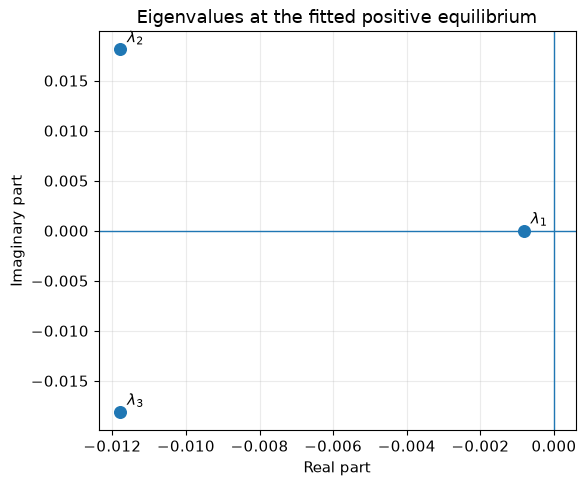

In [11]:
fig,ax=plt.subplots(figsize=(6,5))
ax.scatter(lam.real,lam.imag,s=70)
ax.axvline(0,lw=1)
ax.axhline(0,lw=1)
for i,zv in enumerate(lam,1):
    ax.annotate(fr"$\lambda_{i}$",(zv.real,zv.imag),xytext=(5,5),textcoords="offset points")
ax.set_xlabel("Real part")
ax.set_ylabel("Imaginary part")
ax.set_title("Eigenvalues at the fitted positive equilibrium")
fig.tight_layout()
fig.savefig(FIGDIR/"eigenvalue_complex_plane.png",dpi=300,bbox_inches="tight")
plt.show()

## 6. Numerical continuation in price-adjustment speed

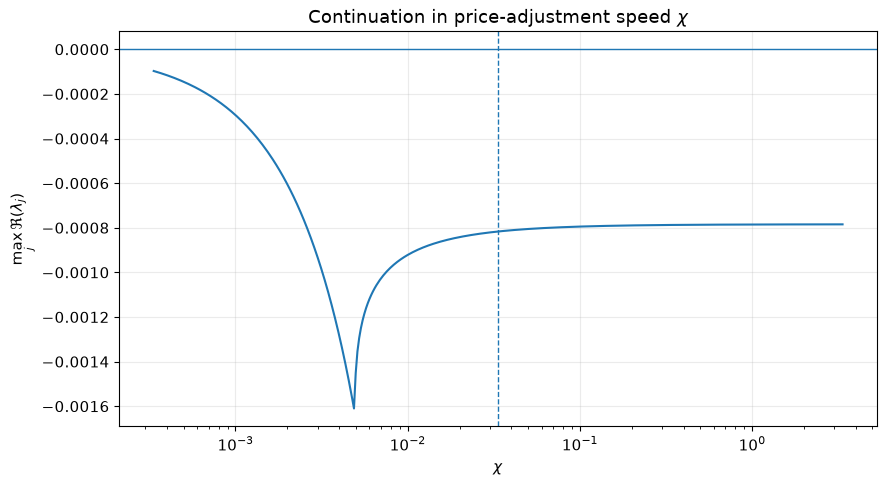

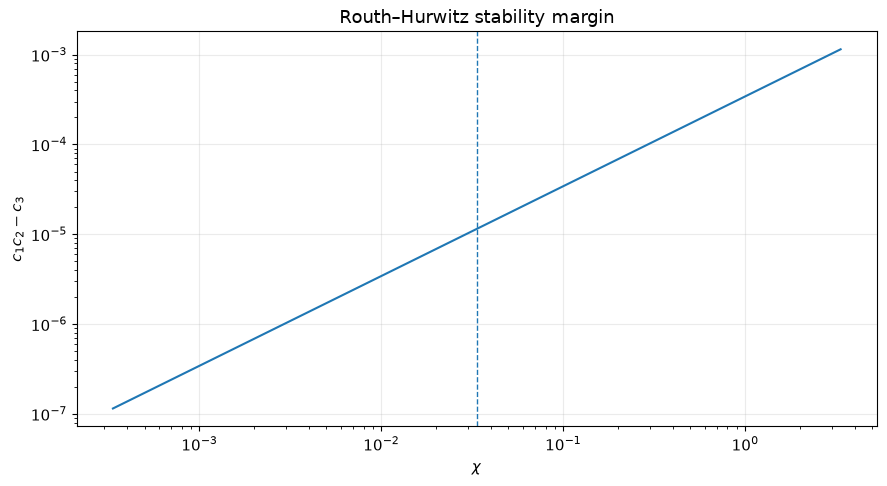

Minimum margin: 1.1480564533941683e-07
Any nonnegative spectral abscissa? False


In [12]:
chi0=theta_full[7]
chi_grid=np.geomspace(max(chi0/100,1e-6),chi0*100,400)
max_real=[]
rh_margin=[]

for ch in chi_grid:
    th=theta_full.copy(); th[7]=ch
    *_,ev,cc1,cc2,cc3,margin,closed=stability_summary(th)
    max_real.append(np.max(np.real(ev)))
    rh_margin.append(margin)

max_real=np.asarray(max_real)
rh_margin=np.asarray(rh_margin)

fig,ax=plt.subplots()
ax.semilogx(chi_grid,max_real,lw=1.5)
ax.axhline(0,lw=1)
ax.axvline(chi0,ls="--",lw=1)
ax.set_xlabel(r"$\chi$")
ax.set_ylabel(r"$\max_j \Re(\lambda_j)$")
ax.set_title(r"Continuation in price-adjustment speed $\chi$")
fig.tight_layout()
fig.savefig(FIGDIR/"continuation_chi_spectral_abscissa.png",dpi=300,bbox_inches="tight")
plt.show()

fig,ax=plt.subplots()
ax.loglog(chi_grid,rh_margin,lw=1.5)
ax.axvline(chi0,ls="--",lw=1)
ax.set_xlabel(r"$\chi$")
ax.set_ylabel(r"$c_1c_2-c_3$")
ax.set_title("Routh–Hurwitz stability margin")
fig.tight_layout()
fig.savefig(FIGDIR/"rh_margin_chi.png",dpi=300,bbox_inches="tight")
plt.show()

print("Minimum margin:",rh_margin.min())
print("Any nonnegative spectral abscissa?",bool(np.any(max_real>=0)))

## 7. Local and global sensitivity analysis

In [13]:
def diagnostics(theta):
    try:
        q,p,Om=equilibrium(theta)
        if not np.isfinite([q,p,Om]).all() or q<=0 or p<=0:
            return [np.nan]*4
        sa=float(np.max(eigvals(jacobian_eq(theta)).real))
        pr=simulate(theta,t,x0)
        if pr is None:
            return [np.nan]*4
        sse=float(np.sum((pr-Y)**2))
        return q,p,sa,sse
    except Exception:
        return [np.nan]*4

base=np.asarray(diagnostics(theta_full))
rows=[]
for j,pname in enumerate(FULL_NAMES):
    for frac in (-.10,.10):
        th=theta_full.copy(); th[j]*=(1+frac)
        vals=np.asarray(diagnostics(th))
        rel=(vals-base)/np.where(np.abs(base)>1e-14,np.abs(base),1)
        rows.append([pname,frac,*vals,*rel])

local_sens=pd.DataFrame(rows,columns=[
    "Parameter","Perturbation","q_star","p_star","spectral_abscissa","SSE",
    "rel_q","rel_p","rel_spectral","rel_SSE"
])
display(local_sens)
local_sens.to_csv(TABDIR/"local_sensitivity_pm10.csv",index=False)

,Parameter,Perturbation,q_star,p_star,spectral_abscissa,SSE,rel_q,rel_p,rel_spectral,rel_SSE
0,rho,-0.1,4.581794,2.972904,-0.000719,73.275759,-1.152060e-01,-1.000000e-01,1.200932e-01,1.566079e-02
1,rho,0.1,5.774953,3.633549,-0.000916,73.327964,1.152060e-01,1.000000e-01,-1.215284e-01,1.638438e-02
2,a,-0.1,5.178373,3.303226,-0.000817,72.145897,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
3,a,0.1,5.178373,3.303226,-0.000817,72.145897,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
4,nu,-0.1,5.841239,3.670251,-0.000833,72.224321,1.280066e-01,1.111111e-01,-2.027177e-02,1.087018e-03
5,nu,0.1,4.636028,3.002933,-0.000800,72.221835,-1.047327e-01,-9.090909e-02,2.002637e-02,1.052562e-03
6,mu,-0.1,5.257115,3.303226,-0.000830,74.197918,1.520598e-02,0.000000e+00,-1.654449e-02,2.844265e-02
7,mu,0.1,5.099631,3.303226,-0.000803,74.217566,-1.520598e-02,0.000000e+00,1.647812e-02,2.871499e-02
8,b,-0.1,5.753748,3.303226,-0.000817,74.115328,1.111111e-01,0.000000e+00,-2.960197e-14,2.729789e-02
9,b,0.1,4.707612,3.303226,-0.000817,73.991882,-9.090909e-02,-1.344410e-16,2.323024e-14,2.558682e-02


Valid Monte Carlo draws: 400/400 (100.0%)


,q_star,p_star,spectral_abscissa,SSE
rho,0.482652,0.693488,-0.961244,0.064642
a,0.071731,0.071102,-0.081089,0.029642
nu,-0.517766,-0.707694,0.153164,0.039521
mu,-0.000728,0.069680,0.118525,0.003338
b,-0.422075,0.014935,-0.030826,0.021693
zeta,0.036542,0.047718,-0.046708,0.012609
eta,0.530798,-0.011157,-0.149561,-0.130210
chi,-0.024956,-0.002073,0.041098,0.080357


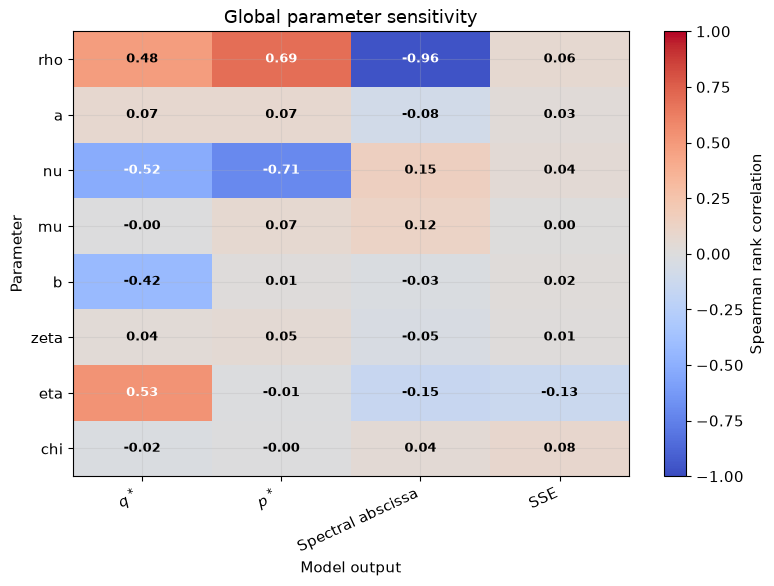

In [14]:
# Global Monte Carlo screen around fitted full parameter vector.
# Each multiplier lies between 1/1.3 and 1.3 on the log scale.
M=MC_SENSITIVITY
srng=np.random.default_rng(SEED+30)
Z=srng.uniform(-1,1,size=(M,8))
Theta_mc=theta_full[None,:]*np.exp(Z*np.log(1.3))

records=[]
for th in Theta_mc:
    records.append([*th,*diagnostics(th)])

mc=pd.DataFrame(records,columns=FULL_NAMES+["q_star","p_star","spectral_abscissa","SSE"])
mc=mc.replace([np.inf,-np.inf],np.nan).dropna()
print(f"Valid Monte Carlo draws: {len(mc)}/{M} ({len(mc)/M:.1%})")

rankcorr=mc.corr(method="spearman").loc[
    FULL_NAMES,["q_star","p_star","spectral_abscissa","SSE"]
]
display(rankcorr)

fig,ax=plt.subplots(figsize=(8,6))
im=ax.imshow(rankcorr.values,aspect="auto",vmin=-1,vmax=1,cmap="coolwarm")
ax.set_xticks(np.arange(4))
ax.set_xticklabels([r"$q^*$",r"$p^*$","Spectral abscissa","SSE"],rotation=25,ha="right")
ax.set_yticks(np.arange(8))
ax.set_yticklabels(FULL_NAMES)

for i in range(rankcorr.shape[0]):
    for j in range(rankcorr.shape[1]):
        value=rankcorr.iloc[i,j]
        ax.text(j,i,f"{value:.2f}",ha="center",va="center",
                color="white" if abs(value)>=.50 else "black",
                fontsize=9,fontweight="bold")

cbar=fig.colorbar(im,ax=ax)
cbar.set_label("Spearman rank correlation")
ax.set_title("Global parameter sensitivity")
ax.set_xlabel("Model output")
ax.set_ylabel("Parameter")
fig.tight_layout()
fig.savefig(FIGDIR/"global_sensitivity_heatmap.png",dpi=300,bbox_inches="tight")
plt.show()

rankcorr.to_csv(TABDIR/"global_sensitivity_rank_correlations.csv")

## 8. Chronological structural extrapolation

This retains the demanding 80/20 experiment: fit once on the first 388 months and propagate freely through the final 97 months. It should be described as **long-horizon structural extrapolation**, not as a conventional one-step forecasting exercise.

01/4: SSE=29.324742 success=True
02/4: SSE=29.324744 success=True
03/4: SSE=29.324743 success=True
04/4: SSE=29.324757 success=True


SSE      RMSE       MAE        R2
Sample      State                                          
Calibration Demand   2.326934  0.077442  0.058721 -0.013226
            Supply   3.193497  0.090723  0.070143  0.732921
            Price   23.804310  0.247692  0.172168  0.835271
Validation  Demand   3.205324  0.181782  0.174780 -7.678292
            Supply  14.962027  0.392744  0.349271 -7.402681
            Price   92.455116  0.976292  0.866811 -6.213928

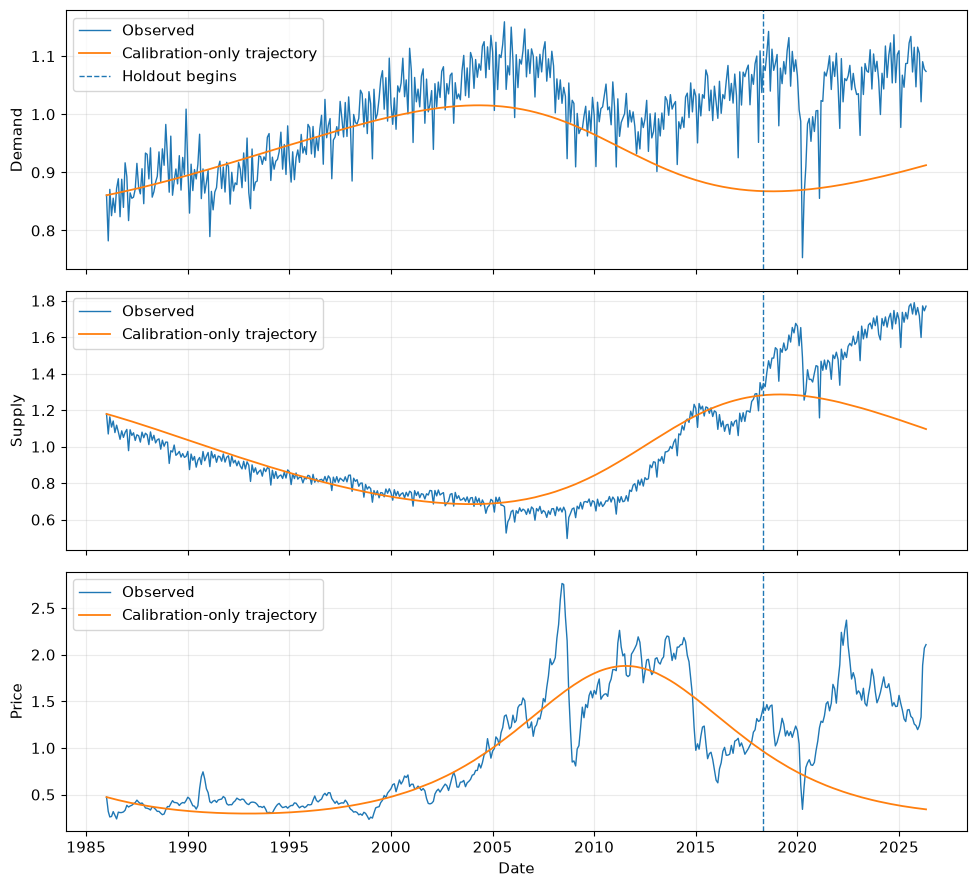

In [15]:
n_train=int(np.floor(.80*len(df)))
t_tr,Y_tr=t[:n_train],Y[:n_train]
t_va,Y_va=t[n_train:],Y[n_train:]

theta_train,fit_train,pred_tr_fit=multistart_fit(
    full_to_reduced(theta_reduced),t_tr,Y_tr,Y_tr[0],reduced=True,
    n_starts=4 if FAST_MODE else 20,max_nfev=1500 if FAST_MODE else 4000,
    seed=SEED+40
)

pred_all=simulate(theta_train,t,Y[0])
pred_tr=pred_all[:n_train]
pred_va=pred_all[n_train:]

long_validation=pd.concat({
    "Calibration":state_metrics(Y_tr,pred_tr),
    "Validation":state_metrics(Y_va,pred_va)
},names=["Sample","State"])
display(long_validation)
long_validation.to_csv(TABDIR/"long_horizon_structural_validation.csv")

fig,axes=plt.subplots(3,1,figsize=(10,9),sharex=True)
for j,ax in enumerate(axes):
    ax.plot(df.date,Y[:,j],lw=1,label="Observed")
    ax.plot(df.date,pred_all[:,j],lw=1.3,label="Calibration-only trajectory")
    ax.axvline(df.date.iloc[n_train],ls="--",lw=1,label="Holdout begins" if j==0 else None)
    ax.set_ylabel(STATE_NAMES[j])
    ax.legend()
axes[-1].set_xlabel("Date")
fig.tight_layout()
fig.savefig(FIGDIR/"out_of_sample_propagation.png",dpi=300,bbox_inches="tight")
plt.show()

## 9. Rolling-origin short-horizon forecasting with persistence benchmark

This is the key empirical strengthening. For each forecast origin in the final 97 months, the reduced model is refitted using information available up to that origin and forecasts are produced for \(h=1,3,6,12\) months. Forecast RMSE and MAE are compared with a persistence benchmark that carries the last observed state forward.

Because monthly ODE states are observed on an integer grid, each forecast simulation begins at the observed state at the forecast origin.

In [16]:
HORIZONS=[1,3,6,12]
origins=range(n_train-1,len(df)-max(HORIZONS))
forecast_rows=[]
prev_start=full_to_reduced(theta_train)

for count,origin in enumerate(origins,1):
    t_est=t[:origin+1]
    Y_est=Y[:origin+1]

    # Warm-started reduced-model refit.
    theta_o,fit_o,_=multistart_fit(
        prev_start,t_est,Y_est,Y_est[0],reduced=True,
        n_starts=ROLLING_REFIT_STARTS,
        max_nfev=700 if FAST_MODE else 1800,
        seed=SEED+1000+origin
    )
    prev_start=full_to_reduced(theta_o)

    # Forecast from the ACTUAL state at the origin.
    local_grid=np.arange(0,max(HORIZONS)+1,dtype=float)
    pred_path=simulate(theta_o,local_grid,Y[origin])

    for h in HORIZONS:
        target=Y[origin+h]
        model_fc=pred_path[h]
        persist_fc=Y[origin]
        for j,state in enumerate(STATE_NAMES):
            forecast_rows.append([
                df.date.iloc[origin],h,state,target[j],
                model_fc[j],persist_fc[j],
                model_fc[j]-target[j],persist_fc[j]-target[j]
            ])

    if count%10==0:
        print(f"Completed {count} forecast origins")

fc=pd.DataFrame(forecast_rows,columns=[
    "Origin","Horizon","State","Actual","ModelForecast","PersistenceForecast",
    "ModelError","PersistenceError"
])

def forecast_summary(g):
    rmse_m=np.sqrt(np.mean(g.ModelError**2))
    rmse_p=np.sqrt(np.mean(g.PersistenceError**2))
    mae_m=np.mean(np.abs(g.ModelError))
    mae_p=np.mean(np.abs(g.PersistenceError))
    return pd.Series({
        "Model_RMSE":rmse_m,"Persistence_RMSE":rmse_p,
        "RMSE_ratio":rmse_m/rmse_p if rmse_p>0 else np.nan,
        "Model_MAE":mae_m,"Persistence_MAE":mae_p,
        "MAE_ratio":mae_m/mae_p if mae_p>0 else np.nan,
        "N_forecasts":len(g)
    })

fc_summary=fc.groupby(["Horizon","State"]).apply(forecast_summary).reset_index()
display(fc_summary)
fc.to_csv(TABDIR/"rolling_origin_forecasts.csv",index=False)
fc_summary.to_csv(TABDIR/"rolling_origin_forecast_summary.csv",index=False)

01/2: SSE=29.324742 success=True
02/2: SSE=29.324741 success=True
01/2: SSE=29.603839 success=True
02/2: SSE=29.603914 success=True
01/2: SSE=29.840814 success=True
02/2: SSE=29.840372 success=True
01/2: SSE=30.164706 success=True
02/2: SSE=30.164685 success=True
01/2: SSE=30.467188 success=True
02/2: SSE=30.462448 success=True
01/2: SSE=30.747552 success=True
02/2: SSE=30.747554 success=True
01/2: SSE=31.086537 success=True
02/2: SSE=31.086537 success=True
01/2: SSE=31.202265 success=True
02/2: SSE=31.202265 success=True
01/2: SSE=31.297983 success=True
02/2: SSE=31.297983 success=True
01/2: SSE=31.401188 success=True
02/2: SSE=34.105696 success=True
Completed 10 forecast origins
01/2: SSE=31.452275 success=True
02/2: SSE=31.452275 success=True
01/2: SSE=31.606816 success=True
02/2: SSE=31.606816 success=True
01/2: SSE=31.825184 success=True
02/2: SSE=31.825184 success=True
01/2: SSE=32.030117 success=True
02/2: SSE=32.030117 success=True
01/2: SSE=32.138079 success=True
02/2: SSE=32.

,Horizon,State,Model_RMSE,Persistence_RMSE,RMSE_ratio,Model_MAE,Persistence_MAE,MAE_ratio,N_forecasts
0,1,Demand,0.063651,0.063634,1.000279,0.048916,0.048915,1.000018,86.0
1,1,Price,0.129675,0.129712,0.999715,0.104059,0.103683,1.003625,86.0
2,1,Supply,0.092258,0.092782,0.994353,0.069793,0.070012,0.996873,86.0
3,3,Demand,0.073543,0.073626,0.998875,0.053074,0.053074,0.999999,86.0
4,3,Price,0.247069,0.247990,0.996288,0.181688,0.180953,1.004065,86.0
5,3,Supply,0.098959,0.101161,0.978228,0.071123,0.073787,0.963897,86.0
6,6,Demand,0.089909,0.090262,0.996090,0.064509,0.064954,0.993149,86.0
7,6,Price,0.321759,0.322799,0.996778,0.245677,0.252000,0.974907,86.0
8,6,Supply,0.124313,0.128686,0.966016,0.094516,0.100541,0.940067,86.0
9,12,Demand,0.077195,0.078639,0.981633,0.048267,0.049526,0.974587,86.0


Horizon,1,3,6,12
State,,,,
Demand,1.000279,0.998875,0.996090,0.981633
Price,0.999715,0.996288,0.996778,1.026093
Supply,0.994353,0.978228,0.966016,0.920701


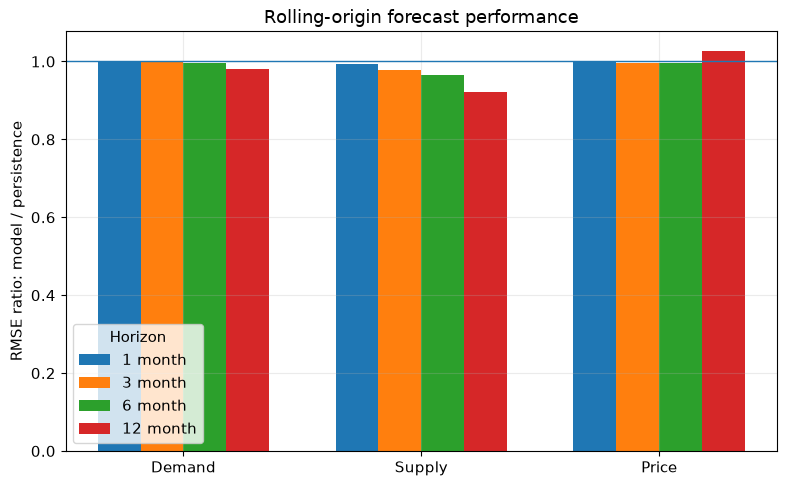

In [17]:
# Plot RMSE ratios: values < 1 favor the nonlinear model over persistence.
pivot=fc_summary.pivot(index="State",columns="Horizon",values="RMSE_ratio")
display(pivot)

fig,ax=plt.subplots(figsize=(8,5))
x=np.arange(len(STATE_NAMES))
width=.18
for k,h in enumerate(HORIZONS):
    ax.bar(x+(k-1.5)*width,pivot[h].reindex(STATE_NAMES).values,width,label=f"{h} month")
ax.axhline(1,lw=1)
ax.set_xticks(x)
ax.set_xticklabels(STATE_NAMES)
ax.set_ylabel("RMSE ratio: model / persistence")
ax.set_title("Rolling-origin forecast performance")
ax.legend(title="Horizon")
fig.tight_layout()
fig.savefig(FIGDIR/"rolling_origin_rmse_ratios.png",dpi=300,bbox_inches="tight")
plt.show()

## 10. Price-growth and imbalance diagnostic with HAC inference

HAC slope=0.026254, SE=0.033961, p=0.4399, 95% CI=(-0.040475,0.092983)


,Slope,SE,CI_low,CI_high,p_value,Inference
0,0.026254,0.033961,-0.040475,0.092983,0.43986,HAC(12)


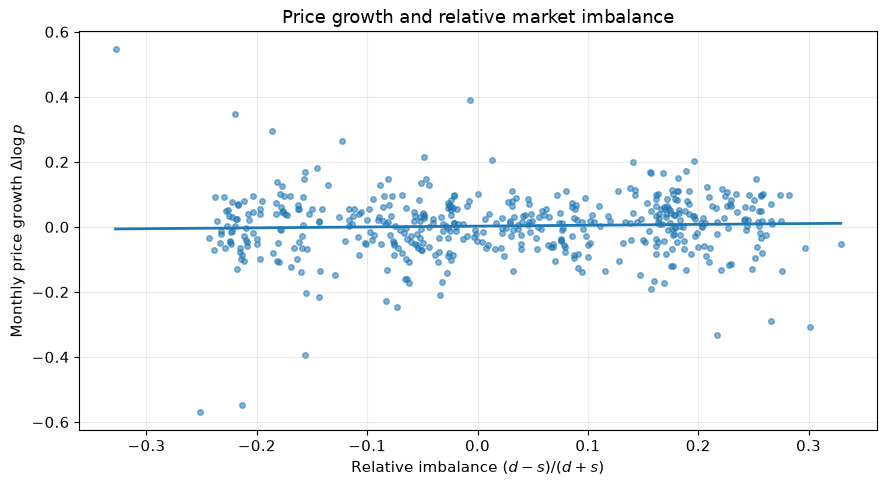

In [18]:
imb=((df.d-df.s)/(df.d+df.s)).to_numpy()
dlogp=np.diff(np.log(df.p.to_numpy()))
X=imb[:-1]

if HAVE_STATSMODELS:
    Xmat=sm.add_constant(X)
    ols=sm.OLS(dlogp,Xmat).fit()
    hac=ols.get_robustcov_results(cov_type="HAC",maxlags=12)
    slope=float(hac.params[1])
    se=float(hac.bse[1])
    pval=float(hac.pvalues[1])
    ci=hac.conf_int(alpha=.05)[1]
    print(f"HAC slope={slope:.6f}, SE={se:.6f}, p={pval:.4f}, 95% CI=({ci[0]:.6f},{ci[1]:.6f})")
else:
    slope=np.sum((X-X.mean())*(dlogp-dlogp.mean()))/np.sum((X-X.mean())**2)
    intercept=dlogp.mean()-slope*X.mean()
    e=dlogp-(intercept+slope*X)
    s2=np.sum(e**2)/(len(X)-2)
    se=np.sqrt(s2/np.sum((X-X.mean())**2))
    pval=np.nan
    ci=(slope-1.96*se,slope+1.96*se)
    print("statsmodels unavailable; conventional OLS inference shown instead.")

diag=pd.DataFrame([{
    "Slope":slope,"SE":se,"CI_low":ci[0],"CI_high":ci[1],"p_value":pval,
    "Inference":"HAC(12)" if HAVE_STATSMODELS else "Conventional OLS"
}])
display(diag)
diag.to_csv(TABDIR/"price_growth_imbalance_regression.csv",index=False)

intercept=(dlogp-slope*X).mean()
fig,ax=plt.subplots()
ax.scatter(X,dlogp,s=16,alpha=.55)
xx=np.linspace(X.min(),X.max(),200)
ax.plot(xx,intercept+slope*xx,lw=2)
ax.set_xlabel(r"Relative imbalance $(d-s)/(d+s)$")
ax.set_ylabel(r"Monthly price growth $\Delta\log p$")
ax.set_title("Price growth and relative market imbalance")
fig.tight_layout()
fig.savefig(FIGDIR/"price_growth_imbalance.png",dpi=300,bbox_inches="tight")
plt.show()

## 11. Residual diagnostics

Residual dependence is reported as a model limitation rather than hidden behind independent-error standard errors.

,Demand,Supply,Price
count,485.000000,485.000000,485.000000
mean,-0.026209,0.034114,-0.015641
std,0.068087,0.116357,0.358869
min,-0.374558,-0.287810,-1.084414
25%,-0.070350,-0.056327,-0.201801
50%,-0.026757,0.043658,-0.045494
75%,0.021470,0.111945,0.164810
max,0.127580,0.354008,1.404843


,State,ACF_lag1,ACF_lag12,Mean,SD
0,Demand,0.653987,0.789875,-0.026209,0.068087
1,Supply,0.877641,0.774691,0.034114,0.116357
2,Price,0.961104,0.436332,-0.015641,0.358869


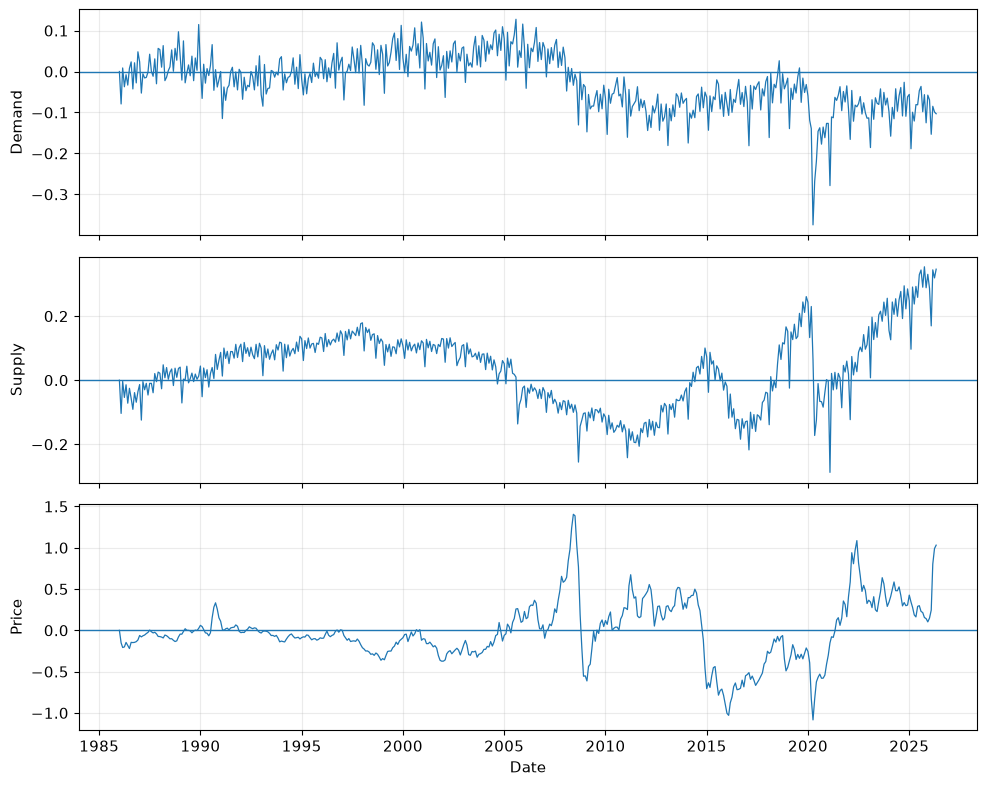

In [19]:
resid=Y-Yhat_reduced
resid_df=pd.DataFrame(resid,columns=STATE_NAMES)
display(resid_df.describe())

diag_rows=[]
for j,name in enumerate(STATE_NAMES):
    r=resid[:,j]
    ac1=np.corrcoef(r[:-1],r[1:])[0,1]
    ac12=np.corrcoef(r[:-12],r[12:])[0,1]
    diag_rows.append([name,ac1,ac12,np.mean(r),np.std(r,ddof=1)])

resid_diag=pd.DataFrame(diag_rows,columns=["State","ACF_lag1","ACF_lag12","Mean","SD"])
display(resid_diag)
resid_diag.to_csv(TABDIR/"residual_diagnostics.csv",index=False)

fig,axes=plt.subplots(3,1,figsize=(10,8),sharex=True)
for j,ax in enumerate(axes):
    ax.plot(df.date,resid[:,j],lw=.9)
    ax.axhline(0,lw=1)
    ax.set_ylabel(STATE_NAMES[j])
axes[-1].set_xlabel("Date")
fig.tight_layout()
fig.savefig(FIGDIR/"residual_time_series.png",dpi=300,bbox_inches="tight")
plt.show()

## 12. Optional stochastic robustness experiment

This section is deliberately **secondary**. It does not create a fitted stochastic model and must not be reported as a calibrated prediction interval. Its sole purpose is to illustrate how random multiplicative disturbances can disperse trajectories around a stable deterministic system.

For a stronger future paper, replace this experiment with a formally estimated stochastic state-space or SDE model.

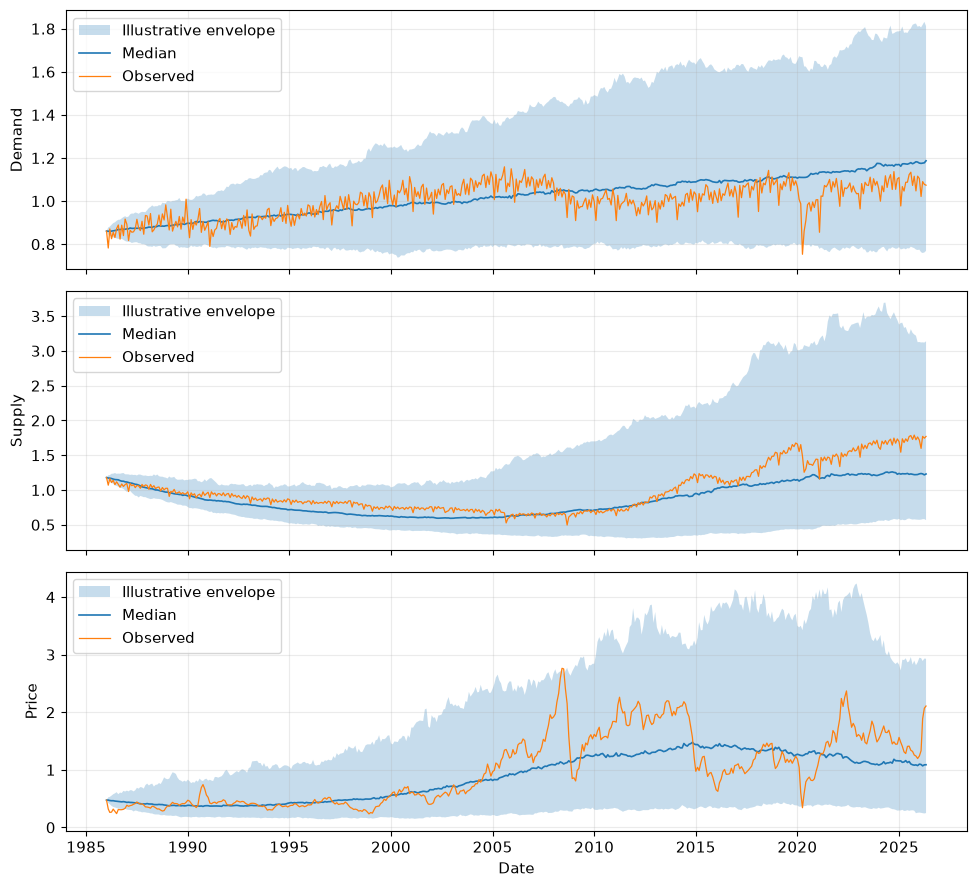

In [22]:
RUN_STOCHASTIC_ILLUSTRATION = True

if RUN_STOCHASTIC_ILLUSTRATION:
    STOCHASTIC_REPS=200 if FAST_MODE else 2000
    sigma=np.std(resid,axis=0,ddof=1)*0.15
    dt=.25
    grid=np.arange(0,t[-1]+dt,dt)
    idx=np.searchsorted(grid,t)
    paths=np.empty((STOCHASTIC_REPS,len(t),3))
    srng=np.random.default_rng(SEED+50)

    def em(theta,xinit,sigma,grid,rng):
        X=np.empty((len(grid),3)); X[0]=xinit
        for k in range(1,len(grid)):
            drift=rhs_autonomous(grid[k-1],X[k-1],theta)
            shock=sigma*np.maximum(X[k-1],1e-8)*np.sqrt(dt)*rng.normal(size=3)
            X[k]=np.maximum(X[k-1]+drift*dt+shock,1e-8)
        return X

    for r in range(STOCHASTIC_REPS):
        paths[r]=em(theta_reduced,x0,sigma,grid,srng)[idx]

    lo,med,hi=np.quantile(paths,[.025,.5,.975],axis=0)
    fig,axes=plt.subplots(3,1,figsize=(10,9),sharex=True)
    for j,ax in enumerate(axes):
        ax.fill_between(df.date,lo[:,j],hi[:,j],alpha=.25,label="Illustrative envelope")
        ax.plot(df.date,med[:,j],lw=1.2,label="Median")
        ax.plot(df.date,Y[:,j],lw=.9,label="Observed")
        ax.set_ylabel(STATE_NAMES[j]); ax.legend()
    axes[-1].set_xlabel("Date")
    fig.tight_layout()
    fig.savefig(FIGDIR/"stochastic_robustness_optional.png",dpi=300,bbox_inches="tight")
    plt.show()
else:
    print("Optional stochastic illustration skipped.")

## 13. Publication summary and reproducibility record

In [21]:
summary={
    "seed":SEED,
    "fast_mode":FAST_MODE,
    "N":int(len(df)),
    "sample_start":str(df.date.min().date()),
    "sample_end":str(df.date.max().date()),
    "full_parameters":dict(zip(FULL_NAMES,map(float,theta_full))),
    "reduced_parameters":dict(zip(FULL_NAMES,map(float,theta_reduced))),
    "SSE_full":SSE_full,
    "SSE_reduced":SSE_red,
    "AIC_full":AIC_full,
    "BIC_full":BIC_full,
    "AIC_reduced":AIC_red,
    "BIC_reduced":BIC_red,
    "equilibrium_q_full":float(qstar),
    "equilibrium_p_full":float(pstar),
    "Omega_full":float(Omega),
    "eigenvalues_full":[str(v) for v in lam],
    "RH_margin_full":float(RH),
    "bootstrap_target":int(BOOTSTRAP_TARGET),
    "bootstrap_successful":int(len(boot)),
    "bootstrap_attempts":int(attempts),
    "bootstrap_success_rate":float(success_rate),
    "MC_sensitivity_requested":int(M),
    "MC_sensitivity_valid":int(len(mc)),
    "price_imbalance_slope":float(slope),
    "price_imbalance_SE":float(se),
    "price_imbalance_p_value":None if not np.isfinite(pval) else float(pval)
}
with open(TABDIR/"analysis_summary.json","w") as f:
    json.dump(summary,f,indent=2)

print(json.dumps(summary,indent=2))
print("\nPublication checklist:")
print("1. Re-run with FAST_MODE=False.")
print("2. Require ~1000 successful bootstrap replications before using percentile CIs.")
print("3. Report reduced-model uncertainty as the main parameter uncertainty result.")
print("4. Report 97-month free run as structural extrapolation, not ordinary forecasting.")
print("5. Report rolling-origin horizon-specific results against persistence.")
print("6. Do not claim a Hopf bifurcation: the analytical result rules out a chi-only Hopf crossing.")
print("7. Keep the optional stochastic envelope explicitly illustrative unless a stochastic model is estimated.")

{
  "seed": 20261015,
  "fast_mode": true,
  "N": 485,
  "sample_start": "1986-01-01",
  "sample_end": "2026-05-01",
  "full_parameters": {
    "rho": 0.000933754818877128,
    "a": 5.967883891558716e-22,
    "nu": 0.0002826796397350284,
    "mu": 0.003708139738801169,
    "b": 0.004709212527193886,
    "zeta": 2.77592819086545e-14,
    "eta": 0.00850507879327165,
    "chi": 0.033514668685879524
  },
  "reduced_parameters": {
    "rho": 0.0009337471962624519,
    "a": 0.0,
    "nu": 0.00028267034219136254,
    "mu": 0.003708108034234067,
    "b": 0.004709231330953616,
    "zeta": 0.0,
    "eta": 0.008505063554915196,
    "chi": 0.03351482261911769
  },
  "SSE_full": 72.1458974746722,
  "SSE_reduced": 72.14589747392088,
  "AIC_full": -4354.922951522691,
  "BIC_full": -4312.660862085846,
  "AIC_reduced": -4358.922951537843,
  "BIC_reduced": -4327.226384460209,
  "equilibrium_q_full": 5.178373247499076,
  "equilibrium_p_full": 3.303226294445505,
  "Omega_full": 1.3311985006150032e-06,
  "